<h1>Apply K-NNN algorithms for the practical problems.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load data
df = pd.read_csv("D:\BDA 20\BDA LAB\AIML-BDA-Lab-Work\AssignmentFiles\data\diabetes.csv")

# 2. Replace invalid zeros with median
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)
df[cols] = df[cols].fillna(df[cols].median())

# 3. Features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# 4. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Best K: 5


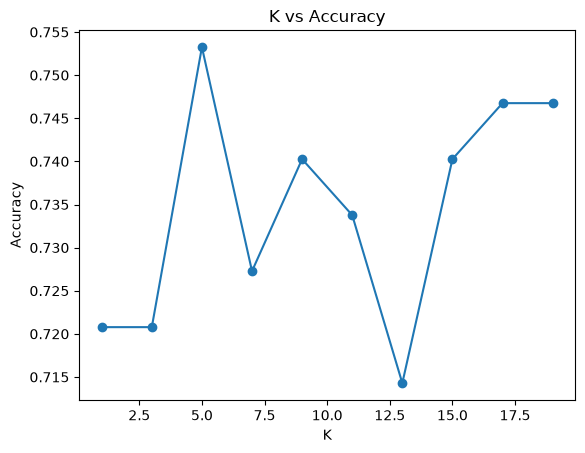

In [10]:
# 5. Scale features (important for K-NN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 6. Find the best K
k_values = range(1, 20,2)
accuracies = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    accuracies.append(accuracy_score(y_test, model.predict(X_test)))

best_k = k_values[int(np.argmax(accuracies))]
print("Best K:", best_k)

plt.plot(k_values, accuracies, marker="o")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy")
plt.show()


In [11]:
# 7. Final model with best K
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

# 8. Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7532467532467533
Confusion Matrix:
 [[83 17]
 [21 33]]
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



## Dataset Selection: Why `diabetes.csv` for K-NN?

### Problem Statement
Predict whether a patient has diabetes (`Outcome` = 1) or not (`Outcome` = 0) based on medical measurements, using the K-Nearest Neighbors (K-NN) algorithm.

### Why this dataset is suitable

| Criterion | How `diabetes.csv` satisfies it |
|-----------|---------------------------------|
| **Classification target** | `Outcome` is binary (0/1), which is the natural use case for K-NN classification |
| **Numeric features** | All 8 features (Glucose, BMI, Age, BloodPressure, Insulin, etc.) are numeric, so distance can be computed directly with no encoding |
| **Practical, real-world problem** | Early diabetes prediction from patient data is a meaningful healthcare application |
| **Adequate size** | 768 records is enough for a train/test split and tuning K, yet small enough for fast K-NN computation |
| **Multiple features** | 8 features give a richer distance calculation than a 2-feature dataset |
| **Demonstrates key K-NN concepts** | Feature scaling, choosing the best K, and evaluation with a confusion matrix and classification report |

### Conclusion
`diabetes.csv` is the best fit because it provides a clean binary classification task with numeric features, a practical real-world context, and enough data to demonstrate every step of the K-NN workflow.